# Tumor subpopulation programs

Each tumor subpopulation is compared with the remaining tumor cells using
model-based scANVI differential expression. The signed `lfc_mean`
ranking is then used for Hallmark preranked GSEA, and the `tumor_4` versus
`tumor_5` pair gets a direct contrast because the shared-vs-rest
comparisons dilute that difference.

In [1]:
from pathlib import Path
import sys

import anndata as ad
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.bio import matching, plots, signatures
from src.utils import load_config

cfg = load_config()
paths = cfg["paths"]
bio = cfg.get("bio", {})
FIG_DIR = ROOT / paths["bio"]["figures"]
FIG_DIR.mkdir(parents=True, exist_ok=True)

GSEA = bio.get("gsea", {})
FORCE_RECOMPUTE = False

## Inputs and matching groups

In [2]:
combined = ad.read_h5ad(ROOT / paths["bio"]["joint_artifact"])
settings = combined.uns["bio_leiden_settings"]
approach = settings["approach"]
config_id = int(settings["config_id"])
num_hvg = int(settings["num_hvg"])
tumor_res = float(settings["tumor_res"])
tumor_key = f"tumor_leiden_res{tumor_res}"

de_dir = ROOT / paths["bio"]["de_joint"]
gsea_dir = de_dir / "gsea_hallmark"
gmt_path = ROOT / paths["bio"]["hallmark_gmt"]
gsea_dir.mkdir(parents=True, exist_ok=True)

group = matching.make_match_groups(combined.obs, tumor_key)
combined.obs["match_group"] = group

run_dir = ROOT / paths["hpo"]["runs"] / f"hvg{num_hvg}" / f"config_{config_id:02d}" / approach
model_dir = run_dir / ("joint_scanvi" if approach == "joint" else "query")

groups_de = combined.obs["match_group"].astype(str).to_numpy()
tumor_subpops = sorted(
    pd.unique(groups_de[combined.obs["dataset"].eq("tumor").to_numpy()]),
    key=matching.tumor_group_sort_key,
)

print(f"model: {model_dir.relative_to(ROOT)}")
print(f"genes: {int(combined.var['hvg'].sum()):,}; tumor subpopulations: {len(tumor_subpops)}")

model: models/hpo/runs/hvg3000/config_10/joint/joint_scanvi
genes: 3,000; tumor subpopulations: 18


## Subpopulation versus remaining tumor

All caches in this notebook live under
`de_dir = models/validation/bio_joint_cfg10/de_signatures`.
`batch_correction=True` is the primary signature. The uncorrected variant
is kept as a sensitivity cache; both are written under
`de_dir/batch_correction_{true,false}/` next to their manifest.

In [3]:
de_by_variant, rankings_by_variant, qc_by_variant = signatures.load_or_run_tumor_de(
    model_dir,
    combined,
    groups_de,
    tumor_subpops,
    de_dir,
    batch_correction_options=(True, False),
    mode="change",
    delta=0.25,
    force=FORCE_RECOMPUTE,
)

PRIMARY_BATCH_CORRECTION = True
de_by_subpop = de_by_variant[PRIMARY_BATCH_CORRECTION]
rankings = rankings_by_variant[PRIMARY_BATCH_CORRECTION]
de_qc = qc_by_variant[PRIMARY_BATCH_CORRECTION]
de_qc.round(3)

loaded batch_correction_true: tumor_0
loaded batch_correction_true: tumor_1
loaded batch_correction_true: tumor_2
loaded batch_correction_true: tumor_3
loaded batch_correction_true: tumor_4
loaded batch_correction_true: tumor_5


loaded batch_correction_true: tumor_6
loaded batch_correction_true: tumor_7
loaded batch_correction_true: tumor_8
loaded batch_correction_true: tumor_9
loaded batch_correction_true: tumor_10
loaded batch_correction_true: tumor_11
loaded batch_correction_true: tumor_12


loaded batch_correction_true: tumor_13
loaded batch_correction_true: tumor_14
loaded batch_correction_true: tumor_15
loaded batch_correction_true: tumor_16
loaded batch_correction_true: tumor_17


loaded batch_correction_false: tumor_0
loaded batch_correction_false: tumor_1
loaded batch_correction_false: tumor_2
loaded batch_correction_false: tumor_3
loaded batch_correction_false: tumor_4
loaded batch_correction_false: tumor_5


loaded batch_correction_false: tumor_6
loaded batch_correction_false: tumor_7
loaded batch_correction_false: tumor_8
loaded batch_correction_false: tumor_9
loaded batch_correction_false: tumor_10
loaded batch_correction_false: tumor_11


loaded batch_correction_false: tumor_12
loaded batch_correction_false: tumor_13
loaded batch_correction_false: tumor_14
loaded batch_correction_false: tumor_15
loaded batch_correction_false: tumor_16
loaded batch_correction_false: tumor_17


,subpopulation,n_source,n_rest,n_genes,n_de_fdr_0.05,n_up_fdr_0.05,n_down_fdr_0.05,max_proba_de,median_abs_lfc,top_up,top_down
0,tumor_0,12126,96005,3000,0,0,0,0.796,0.212,"CYP26A1, TTR, SLC1A2, PCK1, LEFTY1, HSD17B2, F...","UBE2C, RRM2, CDK1, TOP2A, BIRC5, CCNA2, PBK, N..."
1,tumor_1,10323,97808,3000,0,0,0,0.824,0.300,"APCDD1, FN1, LGR5, SMOC2, NOTUM, CYP4X1, NKD1,...","RRM2, CCNA2, UBE2C, CDK1, BIRC5, PBK, CEP55, F..."
2,tumor_2,3276,104855,3000,45,36,9,0.982,0.639,"CA1, UGT2B17, PYY, CA7, SI, MS4A12, BEST4, UGT...","KRTAP3-1, DKK4, REG3A, MYT1, PAEP, BMP7, GAL, ..."
3,tumor_3,7047,101084,3000,0,0,0,0.902,0.436,"EMP1, IGFL1, IGFBP1, RSAD2, KRT17, MMP7, SPRR2...","GP2, DEFA6, GCG, REG1A, RETNLB, L1TD1, PTTG1, ..."
4,tumor_4,11847,96284,3000,0,0,0,0.875,0.290,"RRM2, MYBL2, CDK1, UBE2C, PKMYT1, NPPB, HIST1H...","CLCA1, BEST4, ITLN1, APOA4, S100A8, MNDA, CA7,..."
5,tumor_5,11858,96273,3000,0,0,0,0.902,0.333,"PTTG1, CCNB1, CDC20, CDKN3, BIRC5, CENPF, CCNB...","C17orf78, HPN, PSCA, BCAS1, SNCG, ZG16, CLCA1,..."
6,tumor_6,1461,106670,3000,176,176,0,0.982,0.416,"CPA3, TPSAB1, CCL4, FCN1, CCL17, GNLY, CCL3, G...","RP11-669N7.2, CCL26, PAX4, ITLN1, FABP2, TFF3,..."
7,tumor_7,7357,100774,3000,0,0,0,0.865,0.358,"GOLGA6L2, RP13-516M14.4, POTEC, SCARNA2, MALAT...","CDKN3, CENPW, MAD2L1, CCNB2, BIRC5, PTTG1, CCN..."
8,tumor_8,11922,96209,3000,0,0,0,0.938,0.599,"MNDA, S100A8, RP11-268P4.5, IGFL1, AIF1, TAGLN...","NPPB, AC006004.1, XIST, CHRNA7, NEAT1, SST, SL..."
9,tumor_9,4291,103840,3000,0,0,0,0.946,0.636,"UBE2C, CDK1, PTTG1, BIRC5, CENPA, CCNA2, PBK, ...","SST, AC006004.1, CHRNA7, PYY, XIST, NEAT1, SLC..."


## Hallmark GSEA of the tumor programs

GSEA is run on the full signed `lfc_mean` ranking, not on a thresholded DE list.
The direction summary shows the enriched and depleted Hallmark programs of each
tumor subpopulation at `FDR <= 0.05`. The combined table is saved to
`de_dir/gsea_hallmark/hallmark_prerank_tumor.csv`.

In [4]:
hallmark_sets = signatures.read_gmt(gmt_path)
results_gsea_tumor = signatures.load_or_run_tumor_gsea(
    rankings,
    tumor_subpops,
    gsea_dir,
    gmt_path,
    hallmark_sets,
    seed=0,
    permutations=int(GSEA.get("permutations", 1000)),
    min_size=int(GSEA.get("min_size", 15)),
    max_size=int(GSEA.get("max_size", 500)),
    force=FORCE_RECOMPUTE,
)

print(f"{len(hallmark_sets)} Hallmark sets; {len(results_gsea_tumor)} result rows")
signatures.hallmark_direction_summary(results_gsea_tumor, de_qc, tumor_subpops)

50 Hallmark sets; 810 result rows


,subpopulation,ncells_subpop,n_sig_fdr,n_enriched,n_depleted,top_enriched,top_depleted
0,tumor_0,12126,10,1,9,CHOLESTEROL_HOMEOSTASIS,"G2M_CHECKPOINT, E2F_TARGETS, MITOTIC_SPINDLE"
1,tumor_1,10323,8,0,8,,"E2F_TARGETS, G2M_CHECKPOINT, MITOTIC_SPINDLE"
2,tumor_2,3276,6,0,6,,"E2F_TARGETS, G2M_CHECKPOINT, MYC_TARGETS_V1"
3,tumor_3,7047,24,15,9,"TNFA_SIGNALING_VIA_NFKB, HYPOXIA, APICAL_JUNCTION","G2M_CHECKPOINT, E2F_TARGETS, MITOTIC_SPINDLE"
4,tumor_4,11847,20,13,7,"E2F_TARGETS, G2M_CHECKPOINT, MITOTIC_SPINDLE","INFLAMMATORY_RESPONSE, COAGULATION, PANCREAS_B..."
5,tumor_5,11858,18,12,6,"E2F_TARGETS, G2M_CHECKPOINT, MITOTIC_SPINDLE","KRAS_SIGNALING_DN, INFLAMMATORY_RESPONSE, KRAS..."
6,tumor_6,1461,8,5,3,"ALLOGRAFT_REJECTION, INFLAMMATORY_RESPONSE, CO...","MYC_TARGETS_V1, DNA_REPAIR, OXIDATIVE_PHOSPHOR..."
7,tumor_7,7357,17,0,17,,"G2M_CHECKPOINT, E2F_TARGETS, MYC_TARGETS_V1"
8,tumor_8,11922,4,4,0,"REACTIVE_OXYGEN_SPECIES_PATHWAY, MYC_TARGETS_V...",
9,tumor_9,4291,13,11,2,"G2M_CHECKPOINT, E2F_TARGETS, MYC_TARGETS_V1","TNFA_SIGNALING_VIA_NFKB, INFLAMMATORY_RESPONSE"


## Direct `tumor_4` versus `tumor_5`

The direct head-to-head contrast tests the two proliferative subpopulations
that dominate the candidate table (`lfc_mean > 0` means higher in `tumor_4`).
The DE table is saved to `de_dir/scvi_de_tumor_4_vs_tumor_5.csv`; GSEA to
`de_dir/gsea_hallmark/hallmark_prerank_tumor_4_vs_tumor_5.csv`.

In [5]:
PAIRWISE = ("tumor_4", "tumor_5")
pairwise_de, pairwise_gsea = signatures.load_or_run_pairwise_contrast(
    model_dir,
    combined,
    groups_de,
    PAIRWISE[0],
    PAIRWISE[1],
    de_dir,
    gsea_dir,
    gmt_path,
    hallmark_sets,
    batch_correction=True,
    mode="change",
    delta=0.25,
    seed=0,
    permutations=int(GSEA.get("permutations", 1000)),
    min_size=int(GSEA.get("min_size", 15)),
    max_size=int(GSEA.get("max_size", 500)),
    force=FORCE_RECOMPUTE,
)

print(
    f"{PAIRWISE[0]}: {int(pairwise_de['n_group1'].iloc[0])} cells; "
    f"{PAIRWISE[1]}: {int(pairwise_de['n_group2'].iloc[0])} cells"
)
signatures.pairwise_hallmark_summary(pairwise_gsea, PAIRWISE[0], PAIRWISE[1])

tumor_4: 11847 cells; tumor_5: 11858 cells


,direction,pathway,nes,nom_pval,fdr_qval,overlap,set_size,lead_genes
0,up in tumor_4,ESTROGEN_RESPONSE_EARLY,1.991128,0.000000,0.000000,63,200,REEP1;TIAM1;HSPB8;KCNK15;TFF3;CLIC3;KLK10;MUC1...
1,up in tumor_4,P53_PATHWAY,1.746675,0.000000,0.022197,63,200,ATF3;HBEGF;CDKN1A;NDRG1;TNFSF9;PCNA;MXD1;LIF;E...
2,up in tumor_4,TNFA_SIGNALING_VIA_NFKB,1.732977,0.000000,0.019238,113,200,NR4A1;ATF3;HBEGF;CDKN1A;EGR1;FOSB;TNFSF9;DUSP5...
3,up in tumor_4,UV_RESPONSE_UP,1.665929,0.000000,0.032408,52,158,CCNE1;NR4A1;ATF3;ENO2;FEN1;FOSB;RASGRP1;COL2A1...
4,up in tumor_5,REACTIVE_OXYGEN_SPECIES_PATHWAY,-1.619986,0.036036,0.020050,19,49,PRDX1;SOD1;HHEX;NQO1;TXNRD2;TXN;PRDX2;GCLM;GPX3
5,up in tumor_5,INTERFERON_GAMMA_RESPONSE,-1.719530,0.000000,0.010584,85,200,PSMA3;IDO1;PSMB2;PSME2;CXCL10;CXCL9;CASP1;PSMB...
6,up in tumor_5,SPERMATOGENESIS,-1.797400,0.010490,0.005949,24,135,CCNB2;CDKN3;BUB1;NEK2;LDHC;AURKA;TLE4;SCG3
7,up in tumor_5,INTERFERON_ALPHA_RESPONSE,-1.813599,0.000000,0.005784,44,97,PSMA3;PSME2;CXCL10;CASP1;PSMB8;PSME1;PSMB9;CXC...
8,up in tumor_5,MITOTIC_SPINDLE,-2.079390,0.000000,0.000278,44,199,CCNB2;CENPF;DLGAP5;CENPE;BIRC5;BUB1;KIF4A;PLK1...
9,up in tumor_5,OXIDATIVE_PHOSPHORYLATION,-2.095783,0.000000,0.000347,17,200,HSD17B10;TIMM10;PDK4;COX7B;HCCS;OAT;CYC1;ECH1;...


## Selected-subpopulation GSEA heatmap

The heatmap shows the strongest Hallmark NES values across the candidate and
proliferative tumor subpopulations (`tumor_0`, `tumor_3`, `tumor_4`, `tumor_5`,
`tumor_6`, `tumor_9`, `tumor_12`). The figure is written to
`figures/BIOVAL/tumor_gsea_heatmap.png`.

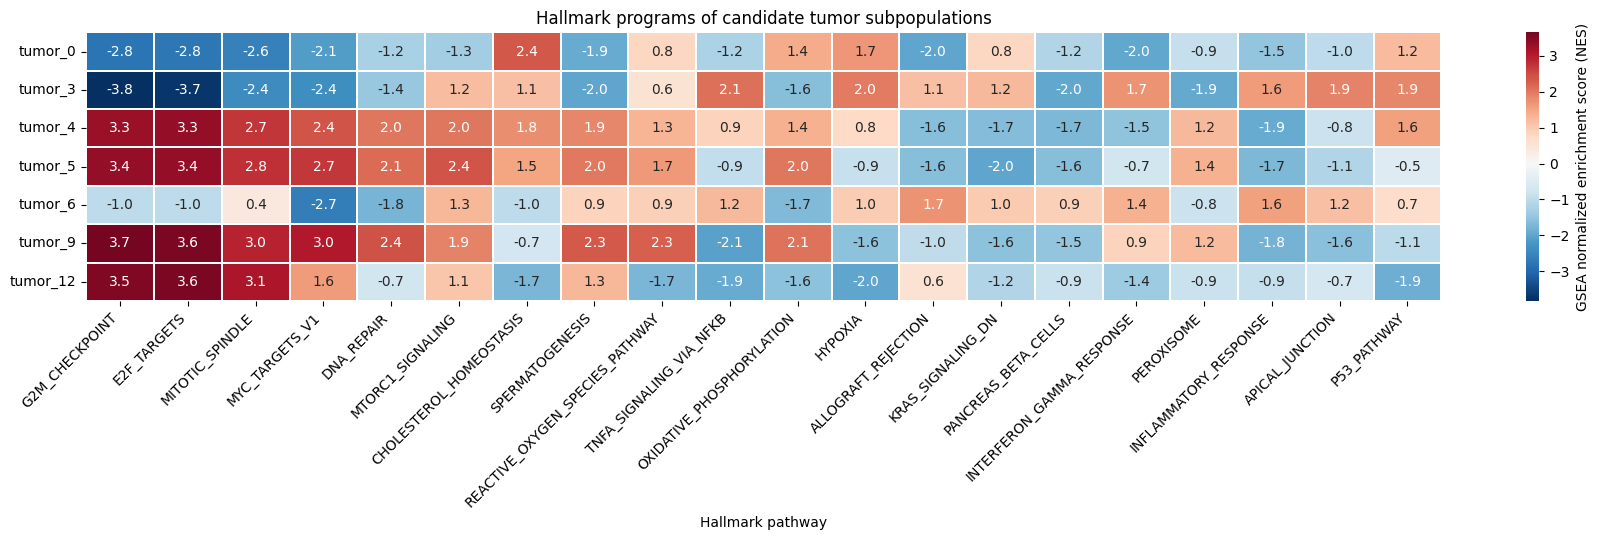

In [6]:
selected_set = {"tumor_0", "tumor_3", "tumor_4", "tumor_5", "tumor_6", "tumor_9", "tumor_12"}
selected = [s for s in tumor_subpops if s in selected_set]

plots.plot_tumor_gsea_heatmap(
    results_gsea_tumor,
    selected,
    n_top=20,
    path=FIG_DIR / "tumor_gsea_heatmap.png",
)
plt.show()